In [1]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
import torch
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
# importlib.reload(prep)
# importlib.reload(func)


In [ ]:
rep = 9 # Use rep9 in sta_entropy, R2=0.82. Use rep1 in diversity, R2=0.83
load_dir = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r{rep}")
#load_dir = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r{rep}")

model = func.load_saved_model_MD(load_dir, device)
evaluator = func.TrteEvaluator(model)

#-------------- Set up test set -------------------------
# #overlap_te = 'Ver1.9/ver1.9.6_upto20_te/10-20_96000'
# overlap_te = 'Ver1.9/ver1.9.6_upto20_te/20-20_102400'
# df_te = pd.read_csv(f'../../Databases/{overlap_te}.csv')
# narray_te = df_te.iloc[:, :-2].values

# folder_te = "../../Databases/Ver1.9/ver1.9.6_upto20_te"
# narray_te, used_files = prep.load_training_dataset_from_folder(folder_te, sample_size=2000, random_state=42)

#split_df = pd.read_csv(f"split_MD_v0/split_MD_{rep}.csv")
split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep}.csv")

folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

narray = prep.load_split_dataset(
    split_df,
    folder_path,
    #richness_list=[spe],
    richness_list=list(range(3,21)),
    subset="te",
    sample_size=80000,
)

# Evaluate the model on the test set
y_te, y_pred = evaluator.predict_array_MD(narray, device, sample_size=None)
metrics = eva.eval_regression(y_te, y_pred)
df_metrics = pd.DataFrame([metrics])
display(df_metrics)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (80000, 465)


,R2,MAE,MedianAE,RMSE,NRMSE,SpearmanR,PearsonR
0,0.816193,0.041522,0.030537,0.060307,0.428727,0.741695,0.904372


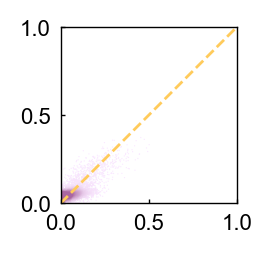

In [17]:
def ScatterPlot(y_te, y_pred, pdfname):
    plt.rcParams.update({
        'font.family': 'Arial',
        'font.size': 8,
        'axes.labelsize': 8, # axis label (text)
        'axes.titlesize': 9,
        'axes.linewidth': 0.5, # axis border line width
        'legend.fontsize': 7, # legend (legend content, not legend title)
        'xtick.major.width': 0.5, # tick line width
        'ytick.major.width': 0.5,
        'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
        'ytick.major.size': 1.5,
        'xtick.labelsize': 8, # x-axis tick label (numbers)
        'ytick.labelsize': 8,
        'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

        'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
        'ps.fonttype': 42
    })

    cmap = LinearSegmentedColormap.from_list(
        "custom_cmap",
        #["#F8D8CC", "#E95920"]
        ["#fae8ff", "#aa67a1"]
    )

    # ==== Calculate point density ====
    figy_true = y_te
    figy_pred = y_pred
    xy = np.vstack([figy_true, figy_pred])
    z = gaussian_kde(xy)(xy)  # density value of each point

    # ==== Sort by density (draw high-density points later so they are not covered) ====
    idx = np.argsort(z)
    x, y, z = figy_true[idx], figy_pred[idx], z[idx]

    # ==== Draw density scatter plot ====
    plt.figure(figsize=(1.1, 1.1), dpi=200)
    # plt.scatter(x, y, c=z, s=10, cmap='Reds', edgecolors='none', alpha=0.9)

    z_norm = (z - np.min(z)) / (np.max(z) - np.min(z))
    threshold = 0.5  # threshold (between 0~1, adjustable)

    # clip
    z_clipped = np.clip(z_norm, 0, threshold) / threshold
    #z_stretch = z_norm ** 0.1  # smaller value gives stronger contrast
    sc = plt.scatter(x, y, c=z_clipped, vmin=0, vmax=1, s=0.2, cmap=cmap, edgecolors='none', alpha=1, rasterized=True)
    #plt.colorbar(sc) # colorbar

    # ==== Draw ideal prediction line ====
    plt.plot([0, 1], [0, 1], "#ffcb5b", lw=1, ls="--")

    # ==== Axis range and labels ====
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    # plt.xlim(1, 3)
    # plt.ylim(1, 3)
    # plt.xlabel("True abundance of species 1", fontsize=9)
    # plt.ylabel("Predicted abundance of species 1", fontsize=9)
    plt.tick_params(direction='in')
    
    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.18,
        top=0.98
    )
    plt.savefig(
        pdfname,
        dpi=1000,
        bbox_inches="tight",
        transparent=True
    )
    plt.show()

#ScatterPlot(y_te, y_pred, f"Sca_H_v3_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")
ScatterPlot(y_te, y_pred, f"Sca_D_v3_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")
